# Train a model

## Load training dataset

In [36]:
from tensorflow import keras
from tensorflow.keras.datasets import mnist
# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Training images shape:", x_train.shape)
print("Training labels shape:", y_train.shape)
print("Testing images shape:", x_test.shape)
print("Testing labels shape:", y_test.shape)

Training images shape: (60000, 28, 28)
Training labels shape: (60000,)
Testing images shape: (10000, 28, 28)
Testing labels shape: (10000,)


## Visualize training data

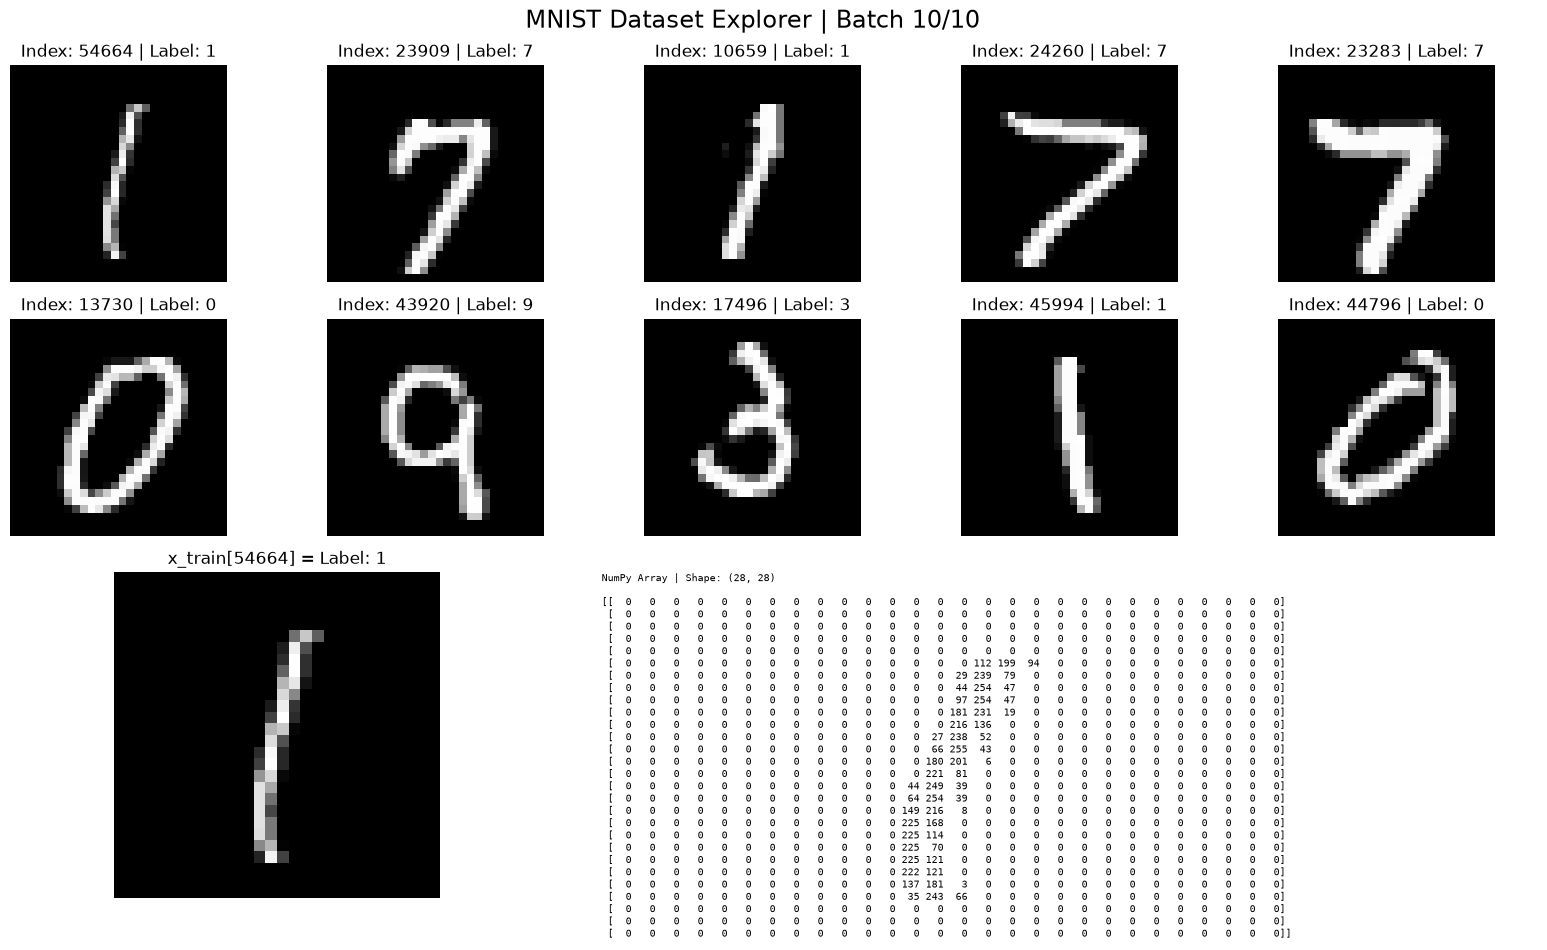

100 random images explored!


In [37]:

import matplotlib.pyplot as plt
import random
import time
import numpy as np
from IPython.display import display, clear_output

images_per_page = 10
delay = 5
total_images = len(x_train)

# Show 100 random images in 10 batches
for page in range(10):

    random_indices = random.sample(range(total_images), images_per_page)

    fig = plt.figure(figsize=(16, 10))

    # Top section: 10 images in 2 rows and 5 columns
    gs = fig.add_gridspec(3, 5, height_ratios=[1, 1, 1.5])

    for i in range(images_per_page):

        row = i // 5
        col = i % 5

        ax = fig.add_subplot(gs[row, col])

        index = random_indices[i]
        img = x_train[index]
        label = y_train[index]

        ax.imshow(img, cmap="gray")
        ax.set_title(f"Index: {index} | Label: {label}")
        ax.axis("off")

    # Bottom left: First selected image
    first_index = random_indices[0]
    first_img = x_train[first_index]
    first_label = y_train[first_index]

    ax_img = fig.add_subplot(gs[2, 0:2])
    ax_img.imshow(first_img, cmap="gray")
    ax_img.set_title(
        f"x_train[{first_index}] = Label: {first_label}",
        fontsize=12
    )
    ax_img.axis("off")

    # Bottom right: Actual numerical pixel representation
    ax_array = fig.add_subplot(gs[2, 2:5])
    ax_array.axis("off")

    pixel_text = np.array2string(
        first_img,
        max_line_width=1000,
        threshold=1000
    )

    ax_array.text(
        0, 1,
        f"NumPy Array | Shape: {first_img.shape}\n\n{pixel_text}",
        fontsize=7,
        family="monospace",
        verticalalignment="top"
    )

    fig.suptitle(
        f"MNIST Dataset Explorer | Batch {page + 1}/10",
        fontsize=17
    )

    plt.tight_layout()

    clear_output(wait=True)
    display(fig)
    plt.close(fig)

    time.sleep(delay)

print("100 random images explored!")


## Normalize for neural network

### Weight adjustments become easier

Neural networks learn by adjusting weights using an optimization algorithm such as Gradient Descent.
If inputs are very large, gradients can become large too, depending on the network architecture and activation functions.
This can make training unstable or require a much smaller learning rate.
With normalized inputs, the numerical scale is generally easier to work with.

### Activation functions work better with appropriately scaled inputs

In [38]:
# Before normalization

min = x_train.min()
max = x_train.max()

print("Before normalization:")
print("Minimum pixel value:", min)
print("Maximum pixel value:", max)
# Normalize
X_train_normalized = x_train / 255.0
X_test_normalized = x_test / 255.0

print("\nAfter normalization:")
print("Minimum pixel value:", X_train_normalized.min())
print("Maximum pixel value:", X_train_normalized.max())

Before normalization:
Minimum pixel value: 0
Maximum pixel value: 255

After normalization:
Minimum pixel value: 0.0
Maximum pixel value: 1.0


## Normalize for CNN

In [39]:
X_train_cnn = X_train_normalized.reshape(-1, 28, 28, 1)
X_test_cnn = X_test_normalized.reshape(-1, 28, 28, 1)

print("CNN training shape:", X_train_cnn.shape)
print("CNN testing shape:", X_test_cnn.shape)

CNN training shape: (60000, 28, 28, 1)
CNN testing shape: (10000, 28, 28, 1)


## Create the CNN model

In [40]:
def create_model(filters):

    model = keras.Sequential([
        keras.layers.Input(shape=(28, 28, 1)),

        keras.layers.Conv2D(
            filters=filters,
            kernel_size=(3, 3),
            activation="relu"
        ),

        keras.layers.MaxPooling2D(pool_size=(2, 2)),

        keras.layers.Flatten(),

        keras.layers.Dense(32, activation="relu"),

        keras.layers.Dense(10, activation="softmax")
    ])

    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

## Train 3 Models with 3 filters

In [41]:

import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping

filter_options = [16, 32, 64]
max_epochs = 15

models = {}
histories = {}
results = []

for filters in filter_options:

    print(f"\nTraining CNN with {filters} filters...")

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = create_model(filters)

    early_stop = EarlyStopping(
        monitor="val_accuracy",
        patience=3,
        mode="max",
        restore_best_weights=True
    )

    history = model.fit(
        X_train_cnn,
        y_train,
        epochs=max_epochs,
        batch_size=64,
        validation_split=0.1,
        callbacks=[early_stop],
        verbose=1
    )

    best_epoch = np.argmax(history.history["val_accuracy"]) + 1
    best_accuracy = np.max(history.history["val_accuracy"])
    best_loss = np.min(history.history["val_loss"])

    models[filters] = model
    histories[filters] = history

    results.append({
        "filters": filters,
        "best_epoch": best_epoch,
        "val_accuracy": best_accuracy,
        "val_loss": best_loss
    })

    print(f"Best epoch: {best_epoch}")
    print(f"Best validation accuracy: {best_accuracy:.4f}")


Training CNN with 16 filters...
Epoch 1/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9173 - loss: 0.2884 - val_accuracy: 0.9707 - val_loss: 0.1049
Epoch 2/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9697 - loss: 0.0986 - val_accuracy: 0.9820 - val_loss: 0.0717
Epoch 3/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9793 - loss: 0.0684 - val_accuracy: 0.9830 - val_loss: 0.0619
Epoch 4/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9839 - loss: 0.0532 - val_accuracy: 0.9842 - val_loss: 0.0589
Epoch 5/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9870 - loss: 0.0435 - val_accuracy: 0.9847 - val_loss: 0.0567
Epoch 6/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9895 - loss: 0.0359 - val_accuracy: 0.9842 - val_loss: 0.0559
Epoch 7/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9912 - loss: 0.0303 - val_accuracy: 0.9837 - val_loss: 0.0566
Epoch 8/15
844/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9930 

## Compare accuracy and loss

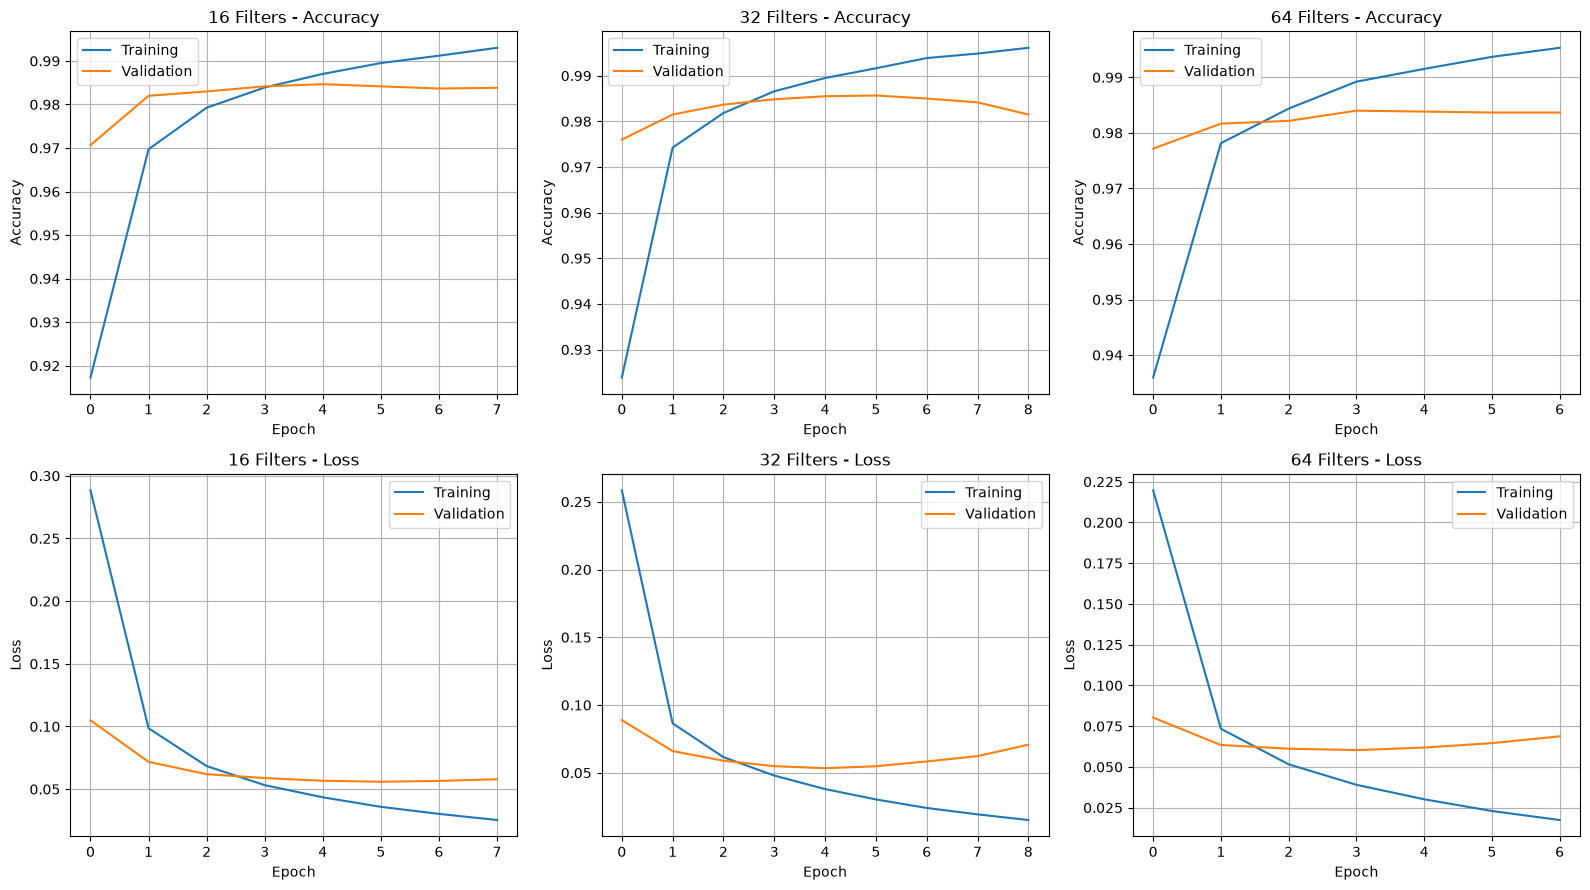

In [42]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for col, filters in enumerate(filter_options):

    history = histories[filters].history

    # Accuracy
    axes[0, col].plot(history["accuracy"], label="Training")
    axes[0, col].plot(history["val_accuracy"], label="Validation")

    axes[0, col].set_title(f"{filters} Filters - Accuracy")
    axes[0, col].set_xlabel("Epoch")
    axes[0, col].set_ylabel("Accuracy")
    axes[0, col].legend()
    axes[0, col].grid()

    # Loss
    axes[1, col].plot(history["loss"], label="Training")
    axes[1, col].plot(history["val_loss"], label="Validation")

    axes[1, col].set_title(f"{filters} Filters - Loss")
    axes[1, col].set_xlabel("Epoch")
    axes[1, col].set_ylabel("Loss")
    axes[1, col].legend()
    axes[1, col].grid()

plt.tight_layout()
plt.show()

## Compare the results

Filters     Best Epoch     Val Accuracy      Val Loss
------------------------------------------------------------
16          5              0.9847            0.0559
32          6              0.9857            0.0534
64          4              0.9840            0.0603


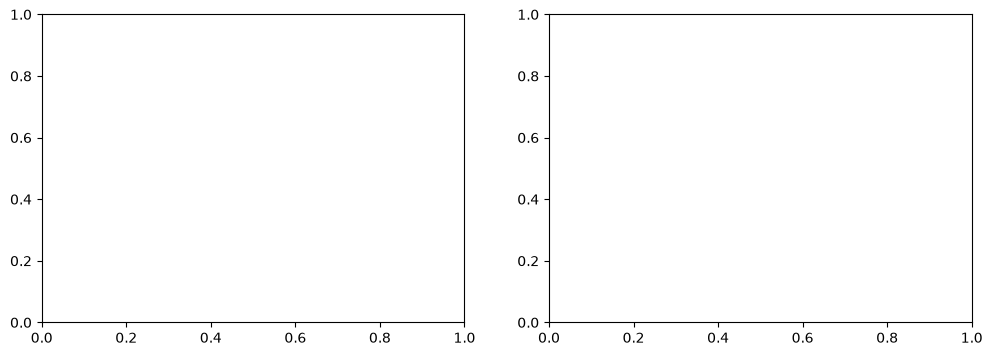

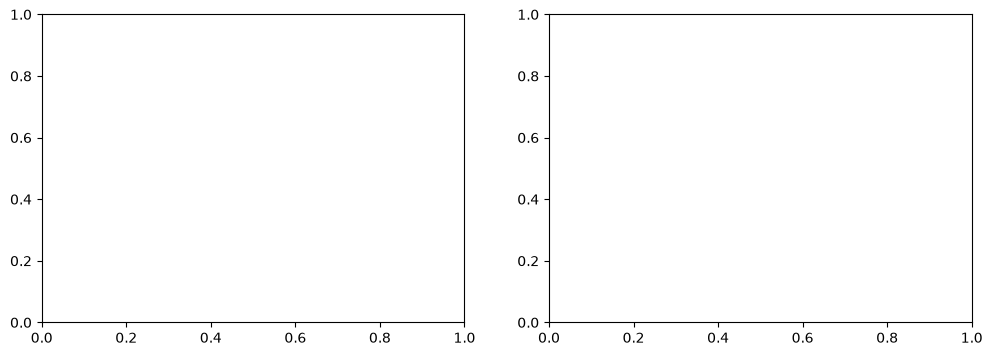

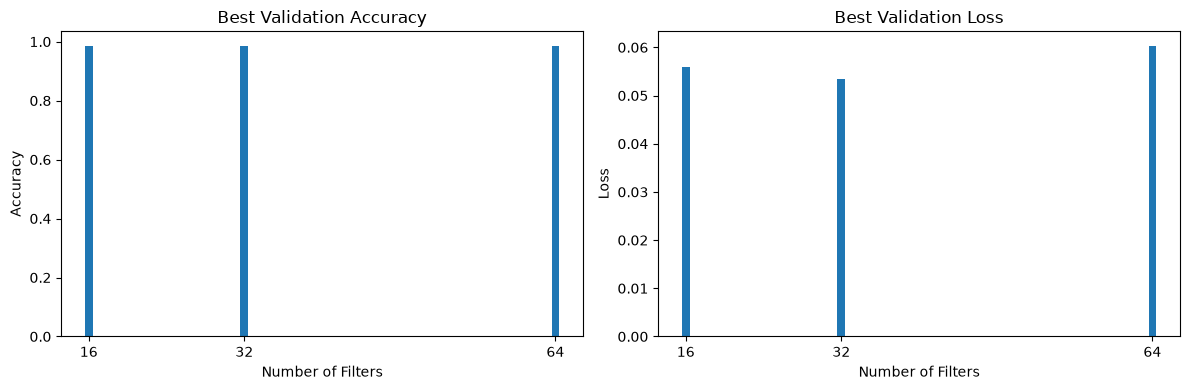

In [43]:
print(f"{'Filters':<12}{'Best Epoch':<15}{'Val Accuracy':<18}{'Val Loss'}")
print("-" * 60)

for result in results:
    print(
        f"{result['filters']:<12}"
        f"{result['best_epoch']:<15}"
        f"{result['val_accuracy']:<18.4f}"
        f"{result['val_loss']:.4f}"
    )

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

filters = [r["filters"] for r in results]
accuracies = [r["val_accuracy"] for r in results]
losses = [r["val_loss"] for r in results]

axes[0].bar(filters, accuracies)
axes[0].set_title("Best Validation Accuracy")
axes[0].set_xlabel("Number of Filters")
axes[0].set_ylabel("Accuracy")
axes[0].set_xticks(filters)

axes[1].bar(filters, losses)
axes[1].set_title("Best Validation Loss")
axes[1].set_xlabel("Number of Filters")
axes[1].set_ylabel("Loss")
axes[1].set_xticks(filters)

plt.tight_layout()
plt.show()

## Select and save the best model

In [44]:
best_result = sorted(
    results,
    key=lambda r: (-r["val_accuracy"], r["val_loss"])
)[0]

best_filters = best_result["filters"]
best_epoch = best_result["best_epoch"]

best_model = models[best_filters]

print("BEST MODEL")
print("Filters:", best_filters)
print("Best Epoch:", best_epoch)
print("Validation Accuracy:", best_result["val_accuracy"])

best_model.save("best_mnist_cnn.keras")

print("\nModel saved successfully!")

BEST MODEL
Filters: 32
Best Epoch: 6
Validation Accuracy: 0.9856666922569275

Model saved successfully!


### Evaluate on unseen test images

In [45]:
test_loss, test_accuracy = best_model.evaluate(
    X_test_cnn,
    y_test,
    verbose=0
)

print("Best Model:", best_filters, "filters")
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", round(test_accuracy * 100, 2))

Best Model: 32 filters
Test Loss: 0.05260330066084862
Test Accuracy: 0.9825000166893005
Test Accuracy (%): 98.25


### Test predictions and confidence levels

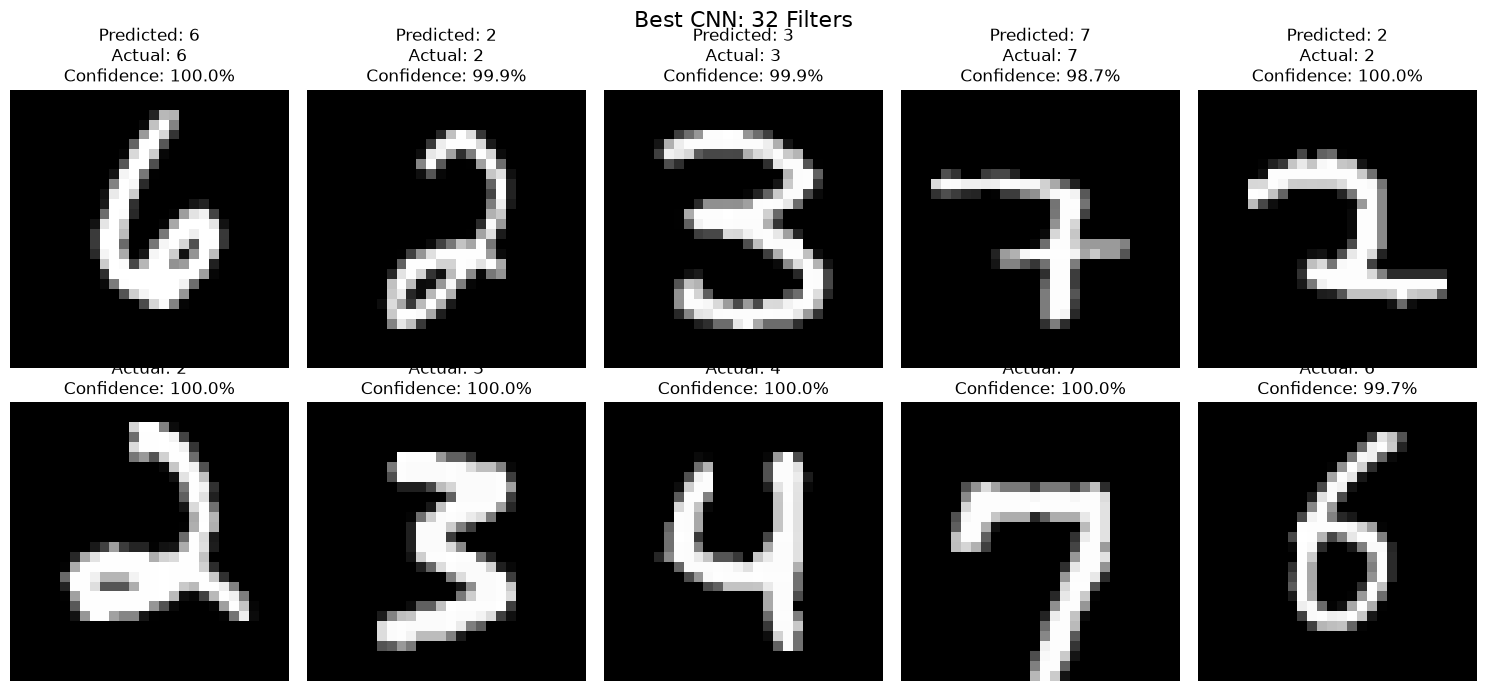

In [46]:
random_indices = np.random.choice(
    len(X_test_cnn),
    10,
    replace=False
)

fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for ax, index in zip(axes.flat, random_indices):

    image = X_test_cnn[index]

    prediction = best_model.predict(
        image.reshape(1, 28, 28, 1),
        verbose=0
    )[0]

    predicted_label = np.argmax(prediction)
    actual_label = y_test[index]
    confidence = prediction[predicted_label] * 100

    ax.imshow(image.squeeze(), cmap="gray")

    ax.set_title(
        f"Predicted: {predicted_label}\n"
        f"Actual: {actual_label}\n"
        f"Confidence: {confidence:.1f}%"
    )

    ax.axis("off")

plt.suptitle(f"Best CNN: {best_filters} Filters", fontsize=16)
plt.tight_layout()
plt.show()

### Inspect confidence for an individual prediction

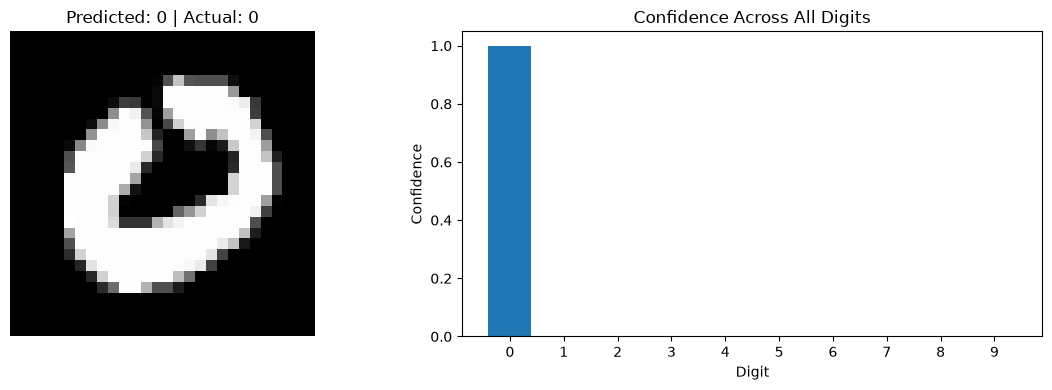

Digit 0: 0.9993
Digit 1: 0.0000
Digit 2: 0.0000
Digit 3: 0.0000
Digit 4: 0.0000
Digit 5: 0.0000
Digit 6: 0.0007
Digit 7: 0.0000
Digit 8: 0.0000
Digit 9: 0.0000


In [47]:
index = 25

prediction = best_model.predict(
    X_test_cnn[index].reshape(1, 28, 28, 1),
    verbose=0
)[0]

predicted_label = np.argmax(prediction)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(X_test_cnn[index].squeeze(), cmap="gray")
plt.title(
    f"Predicted: {predicted_label} | Actual: {y_test[index]}"
)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.bar(range(10), prediction)
plt.xticks(range(10))
plt.xlabel("Digit")
plt.ylabel("Confidence")
plt.title("Confidence Across All Digits")

plt.tight_layout()
plt.show()

for digit, confidence in enumerate(prediction):
    print(f"Digit {digit}: {confidence:.4f}")